# M4.8 · 尾部风险与压力测试（EVT）

> 标准 VaR 只回答「在某置信水平下最多亏多少」，却不描述一旦超过 VaR 会亏多惨；正态假设又系统性低估极端事件。
> 极值理论（EVT）直接对**分布尾部**建模，配合预期亏损 ES 与情景压力测试，刻画真实的尾部风险。

## 一、核心概念

1. **VaR / ES**：$\Pr(L>VaR_\alpha)=\alpha$；$ES_\alpha=E[L\mid L>VaR_\alpha]$，ES 是一致风险度量；
2. **历史法**：直接用经验分位，不假设分布但依赖样本；**正态法**：解析解但尾部偏薄；
3. **POT 超阈值**：对损失超过阈值 $u$ 的部分 $Y=L-u\mid L>u$ 拟合广义帕累托
$$G(y)=1-\left(1+\xi\frac{y}{\beta}\right)^{-1/\xi}$$
形状 $\xi$ 决定尾部厚薄（$\xi>0$ 厚尾）；
4. **GPD 尾部 VaR/ES**：
$$VaR=u+\frac{\beta}{\xi}\left[\left(\frac{n}{N_u}\alpha\right)^{-\xi}-1\right],
\quad ES=\frac{VaR}{1-\xi}+\frac{\beta-\xi u}{1-\xi}$$
5. **压力测试**：人为设定极端情景（如全市场 -10%），直接计算组合损益。

## 二、三种方法的 VaR 与 ES

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import evt
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r1 = ret.iloc[:, 0].dropna()
hv = evt.historical_var_es(r1, 0.05); nv = evt.normal_var_es(r1, 0.05)
gfit = evt.gpd_fit(r1, 0.95); gv = evt.gpd_var_es(r1, 0.01, 0.95)
print('5%%: 历史 VaR=%.4f ES=%.4f | 正态 VaR=%.4f ES=%.4f'
      % (hv['VaR'], hv['ES'], nv['VaR'], nv['ES']))
print('GPD 拟合: 形状xi=%.4f 尺度beta=%.4f 阈值u=%.4f 超额数=%d'
      % (gfit['xi'], gfit['beta'], gfit['u'], gfit['n_excess']))
print('99%%: GPD VaR=%.4f ES=%.4f' % (gv['VaR'], gv['ES']))
alphas = [0.05, 0.025, 0.01, 0.005]
rows = []
for a in alphas:
    h = evt.historical_var_es(r1, a); n = evt.normal_var_es(r1, a); g = evt.gpd_var_es(r1, a, 0.95)
    rows.append((1-a, h['VaR'], n['VaR'], g['VaR']))
var_df = pd.DataFrame(rows, columns=['置信度', '历史VaR', '正态VaR', 'GPD VaR']).set_index('置信度')
print(var_df)

[20036:MainThread](2026-11-05 14:37:58,755) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[20036:MainThread](2026-11-05 14:38:00,688) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[20036:MainThread](2026-11-05 14:38:00,690) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


5%: 历史 VaR=0.0187 ES=0.0284 | 正态 VaR=0.0210 ES=0.0263
GPD 拟合: 形状xi=0.0646 尺度beta=0.0091 阈值u=0.0187 超额数=107
99%: GPD VaR=0.0341 ES=0.0449
          历史VaR     正态VaR   GPD VaR
置信度                                
0.950  0.018688  0.020958  0.018688
0.975  0.024776  0.025000  0.025131
0.990  0.033632  0.029699  0.034104
0.995  0.040884  0.032898  0.041254


## 三、情景压力测试

In [2]:
w50 = pd.Series(np.ones(50)/50, index=ret.iloc[:, :50].columns)
for shock in [-0.05, -0.10, -0.20]:
    st = evt.stress_test(w50, shock)
    print('情景 %+.0f%% -> 组合损益 %+.4f' % (shock*100, st['portfolio_pnl']))

情景 -5% -> 组合损益 -0.0500
情景 -10% -> 组合损益 -0.1000
情景 -20% -> 组合损益 -0.2000


## 四、可视化

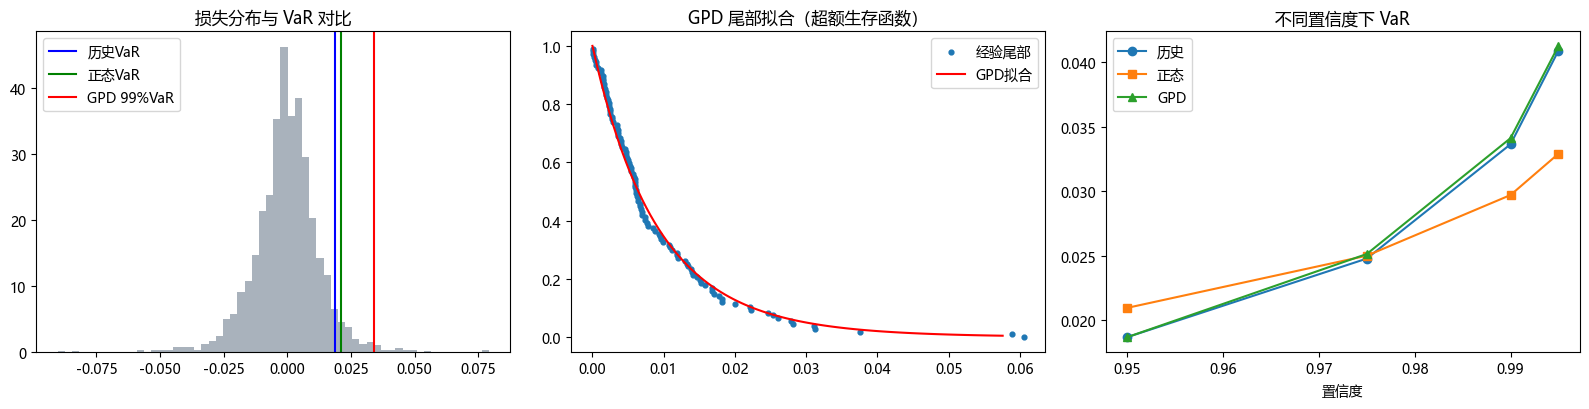

In [3]:
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
L = -r1.values
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(L, bins=60, density=True, alpha=0.6, color='slategray')
for v, lab, c in [(hv['VaR'], '历史VaR', 'blue'), (nv['VaR'], '正态VaR', 'green'),
                  (gv['VaR'], 'GPD 99%VaR', 'red')]:
    ax[0].axvline(v, color=c, label=lab)
ax[0].set_title('损失分布与 VaR 对比'); ax[0].legend()
exc = L[L > gfit['u']] - gfit['u']
xs = np.linspace(0, np.quantile(exc, 0.99), 100)
ax[1].scatter(np.sort(exc), 1-np.arange(1, len(exc)+1)/len(exc), s=12, label='经验尾部')
ax[1].plot(xs, 1-stats.genpareto.cdf(xs, gfit['xi'], 0, gfit['beta']), 'r-', label='GPD拟合')
ax[1].set_title('GPD 尾部拟合（超额生存函数）'); ax[1].legend()
ax[2].plot(var_df.index, var_df['历史VaR'], 'o-', label='历史')
ax[2].plot(var_df.index, var_df['正态VaR'], 's-', label='正态')
ax[2].plot(var_df.index, var_df['GPD VaR'], '^-', label='GPD')
ax[2].set_title('不同置信度下 VaR'); ax[2].set_xlabel('置信度'); ax[2].legend()
plt.tight_layout(); plt.show()

## 五、面试要点

- **为什么 ES 优于 VaR？** VaR 不是一致风险度量（不满足次可加性），且不揭示尾部损失大小；ES 衡量尾部平均损失，满足次可加性。
- **POT 相比块极大值的优势？** 块极大值浪费数据（每块只取一个），POT 利用所有超阈值观测，估计更高效。
- **形状 ξ 的含义？** ξ>0 表示厚尾（如金融收益常见），ξ=0 退化为指数分布，ξ<0 尾部有界。
- **阈值 u 如何选？** 权衡：太高则超额样本少、方差大，太低则 GPD 近似偏差大；常用平均超额函数图（ME plot）辅助。
- **压力测试与 EVT 互补？** EVT 给统计概率，压力测试给「假设情景下的具体损失」，不依赖历史分布。

## 六、练习

1. 改变阈值分位（0.90/0.95/0.99），观察 ξ 与 GPD VaR 的稳定性。
2. 用等权组合收益替代单只股票，比较尾部形状与 VaR。
3. 画出平均超额函数（ME plot）验证阈值选择。
4. 设计一个「行业分化」情景（不同资产不同冲击）并计算组合损益。